In [22]:
# Nombre: Cristina Maureira   Rut: 22.356.447-k
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import string
rng = np.random.default_rng(seed=45578)

In [23]:
# usando rng.uniform se crea los arreglos aleatorios entre los intervalos pedidos con el mismo tamaño
R = rng.uniform(low=0.5,high=5,size=(100,)) # los radios estelares
d = rng.uniform(low=50,high=500,size=(100,)) # las distancias
Teff = rng.uniform(low=3000,high=10000,size=(100,)) # y las temperaturas efectivas

In [24]:
identificador = (i for i in range(1,101)) # el indentificador
dict_1 = {"radio_estelar":R,"distancia":d,"temperatura_efectiva":Teff,"identificador":identificador} # se les pone nombre a las columnas
catalogo = pd.DataFrame(dict_1) # se crea el dataFrame
catalogo_10 = catalogo[catalogo["identificador"]<11] # se acorta el dataFrame a los primeros diez valores
catalogo_10

,radio_estelar,distancia,temperatura_efectiva,identificador
0,2.195127,390.328279,3280.699602,1
1,2.525030,320.044655,6711.525215,2
2,0.791052,452.080362,6552.941373,3
3,4.661126,267.692656,6981.530454,4
4,0.882976,52.809740,7494.190500,5
5,3.833468,232.827044,6266.297411,6
6,4.046042,52.458490,8903.751895,7
7,4.222850,317.143536,5685.457751,8
8,4.237035,291.775865,3587.892165,9
9,0.574196,52.825388,4310.307043,10


In [25]:
catalogo_10.describe() # estadisticas descriptivas del dataFrame

,radio_estelar,distancia,temperatura_efectiva,identificador
count,10.000000,10.000000,10.000000,10.00000
mean,2.796890,242.998602,5977.459341,5.50000
std,1.608328,144.756673,1784.889854,3.02765
min,0.574196,52.458490,3280.699602,1.00000
25%,1.211014,97.825802,4654.094720,3.25000
50%,3.179249,279.734261,6409.619392,5.50000
75%,4.178648,319.319375,6914.029145,7.75000
max,4.661126,452.080362,8903.751895,10.00000


In [26]:
def luminosidad(R, Teff):
    """
    Calcula la luminosidad de una estrella con su radio estelar y temperatura efectiva.

    Parameters
    ----------
    R : float
        Radio estelar.
    Teff : float
        Temperatura efectiva.

    Returns
    -------
    float
        La luminosidad solar de la estrella.
    """
    r = R*6.957*(10**8) # de radio estelar a metros
    sigma = 5.67*(10**-8) # constante de Stefan Boltzmann
    L = 4*np.pi*(r**2)*sigma*(Teff**4)
    return L/(3.828*(10**26)) # pasa de vatios a luminosidad solar
"""
aqui cree una lista que pudiera guardar las luminosidades. En el for se fue agregando con append los valores, el bucle los itera
por fila gracias al iloc, se selecciona la primera y tercera columna que son el radio y la temperatura respectivamente para
usar sus floats en la funcion de luminosidad.
"""
L = []
for i in range(10):
    L.append(luminosidad(catalogo_10.iloc[i].values[0],catalogo_10.iloc[i].values[2]))
# se añade al dataFrame
catalogo_10["luminosidad"]=L
catalogo_10

,radio_estelar,distancia,temperatura_efectiva,identificador,luminosidad
0,2.195127,390.328279,3280.699602,1,0.502864
1,2.525030,320.044655,6711.525215,2,11.654211
2,0.791052,452.080362,6552.941373,3,1.039488
3,4.661126,267.692656,6981.530454,4,46.499596
4,0.882976,52.809740,7494.190500,5,2.215451
5,3.833468,232.827044,6266.297411,6,20.412331
6,4.046042,52.458490,8903.751895,7,92.686805
7,4.222850,317.143536,5685.457751,8,16.785645
8,4.237035,291.775865,3587.892165,9,2.680073
9,0.574196,52.825388,4310.307043,10,0.102522


In [27]:
def flujo(d, L):
    """
    Calcula el flujo observado con la luminosidad y distancia de la estrella.

    Parameters
    ----------
    d : float
        distancia [pc].
    L : float
        luminosidad solar de la estrella.

    Returns
    -------
    float
        flujo observado de la estrella [W*(m**-2)].
    """
    D = d*3.0857*(10**16) # parsecs a metros
    l = L*3.828*(10**26) # luminosidad solar a vatios
    F = l/(4*np.pi*(D**2)) # flujo en vatios por metro cuadrado
    return F
# hice lo mismo que con la luminosidad, solo que con la segunda y quinta columna
F = []
for i in range(10):
    F.append(luminosidad(catalogo_10.iloc[i].values[1],catalogo_10.iloc[i].values[4]))
# se añade al dataFrame
catalogo_10["flujo"]=F
catalogo_10

,radio_estelar,distancia,temperatura_efectiva,identificador,luminosidad,flujo
0,2.195127,390.328279,3280.699602,1,0.502864,8.776586e-12
1,2.525030,320.044655,6711.525215,2,11.654211,1.702228e-06
2,0.791052,452.080362,6552.941373,3,1.039488,2.149685e-10
3,4.661126,267.692656,6981.530454,4,46.499596,3.018107e-04
4,0.882976,52.809740,7494.190500,5,2.215451,6.052593e-11
5,3.833468,232.827044,6266.297411,6,20.412331,8.478173e-06
6,4.046042,52.458490,8903.751895,7,92.686805,1.829651e-04
7,4.222850,317.143536,5685.457751,8,16.785645,7.193311e-06
8,4.237035,291.775865,3587.892165,9,2.680073,3.956856e-09
9,0.574196,52.825388,4310.307043,10,0.102522,2.777319e-16


In [28]:
# estrellas de menor y mayor luminosidad
catalogo_10[(catalogo_10["luminosidad"]==(np.min(catalogo_10["luminosidad"])))|(catalogo_10["luminosidad"]==(np.max(catalogo_10["luminosidad"])))]

,radio_estelar,distancia,temperatura_efectiva,identificador,luminosidad,flujo
6,4.046042,52.458490,8903.751895,7,92.686805,1.829651e-04
9,0.574196,52.825388,4310.307043,10,0.102522,2.777319e-16


In [29]:
# estrellas de menor y mayor flujo
catalogo_10[(catalogo_10["flujo"]==(np.min(catalogo_10["flujo"])))|(catalogo_10["flujo"]==(np.max(catalogo_10["flujo"])))]

,radio_estelar,distancia,temperatura_efectiva,identificador,luminosidad,flujo
3,4.661126,267.692656,6981.530454,4,46.499596,3.018107e-04
9,0.574196,52.825388,4310.307043,10,0.102522,2.777319e-16


In [30]:
flujo_limite = 2*(10**-10)/(3.828*(10**26)) # como el limite estaba en vatios*(m**-2) lo pase a luminosidad solar
catalogo_10["Clasificacion"] = catalogo_10["flujo"].apply(lambda x: "no_detectada" if x < flujo_limite else "detectada" )
catalogo_10

,radio_estelar,distancia,temperatura_efectiva,identificador,luminosidad,flujo,Clasificacion
0,2.195127,390.328279,3280.699602,1,0.502864,8.776586e-12,detectada
1,2.525030,320.044655,6711.525215,2,11.654211,1.702228e-06,detectada
2,0.791052,452.080362,6552.941373,3,1.039488,2.149685e-10,detectada
3,4.661126,267.692656,6981.530454,4,46.499596,3.018107e-04,detectada
4,0.882976,52.809740,7494.190500,5,2.215451,6.052593e-11,detectada
5,3.833468,232.827044,6266.297411,6,20.412331,8.478173e-06,detectada
6,4.046042,52.458490,8903.751895,7,92.686805,1.829651e-04,detectada
7,4.222850,317.143536,5685.457751,8,16.785645,7.193311e-06,detectada
8,4.237035,291.775865,3587.892165,9,2.680073,3.956856e-09,detectada
9,0.574196,52.825388,4310.307043,10,0.102522,2.777319e-16,detectada


In [31]:
conteo = catalogo_10["Clasificacion"].value_counts()["detectada"] # cuantas estrellas fueron detectadas (guarde la frecuencia)
conteo

np.int64(10)

In [32]:
p_detectadas = conteo*100/len(catalogo_10["Clasificacion"]) # cálculo de estrellas detectadas
print(f"porcentaje de estrellas detectadas: {p_detectadas}%")

porcentaje de estrellas detectadas: 100.0%


In [33]:
estrellas_d = catalogo_10[(catalogo_10["Clasificacion"]=="detectada")] # tabla que solo tiene las estrellas detectadas
estrellas_no_d = catalogo_10[(catalogo_10["Clasificacion"]=="no_detectada")] # y la que no
print(f"""Estrellas detectadas
luminosidad promedio: {estrellas_d["luminosidad"].mean():.5}Lo
distancia promedio: {estrellas_d["distancia"].mean():.5}pc
temperatura efectiva: {estrellas_d["temperatura_efectiva"].mean():.5}K
-----------------
Estrellas no detectadas
luminosidad promedio: {estrellas_no_d["luminosidad"].mean():.5}Lo
distancia promedio: {estrellas_no_d["distancia"].mean():.5}pc
temperatura efectiva: {estrellas_no_d["temperatura_efectiva"].mean():.5}K""")
#los que salieron con "nan" es porque la tabla no contenia ningun elemento, por lo tanto no se puede calcular nada sin nada.

Estrellas detectadas
luminosidad promedio: 19.458Lo
distancia promedio: 243.0pc
temperatura efectiva: 5977.5K
-----------------
Estrellas no detectadas
luminosidad promedio: nanLo
distancia promedio: nanpc
temperatura efectiva: nanK


Text(0.5, 1.0, 'histograma de temperaturas efectivas')

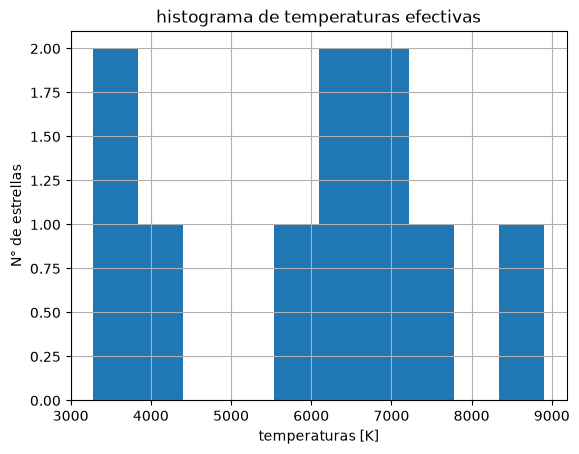

In [77]:
catalogo_10["temperatura_efectiva"].hist() #histograma de temperaturas efectivas
plt.xlabel("temperaturas [K]")
plt.ylabel("N° de estrellas")
plt.title("histograma de temperaturas efectivas")

Text(0.5, 1.0, 'histograma de radios estelares')

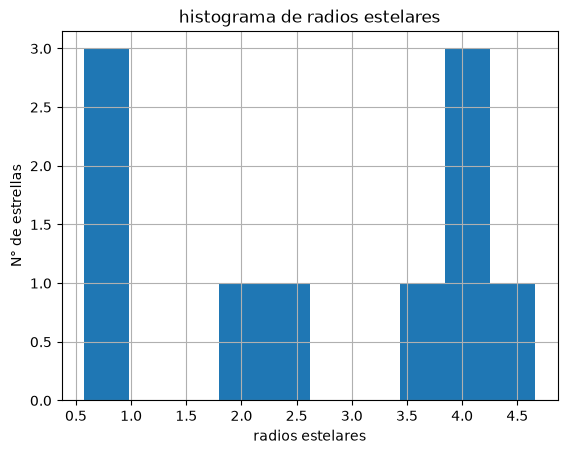

In [78]:
catalogo_10["radio_estelar"].hist() #histograma de radios estelares
plt.xlabel("radios estelares")
plt.ylabel("N° de estrellas")
plt.title("histograma de radios estelares")

Text(0.5, 1.0, 'histograma de distancias')

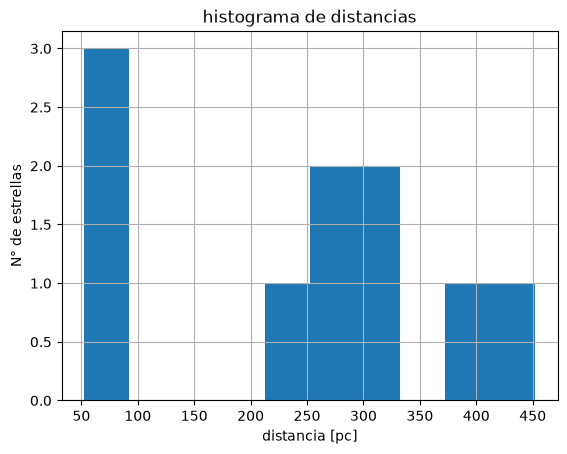

In [79]:
catalogo_10["distancia"].hist() #histograma de distancias
plt.xlabel("distancia [pc]")
plt.ylabel("N° de estrellas")
plt.title("histograma de distancias")

Text(0.5, 1.0, 'histograma de luminosidades')

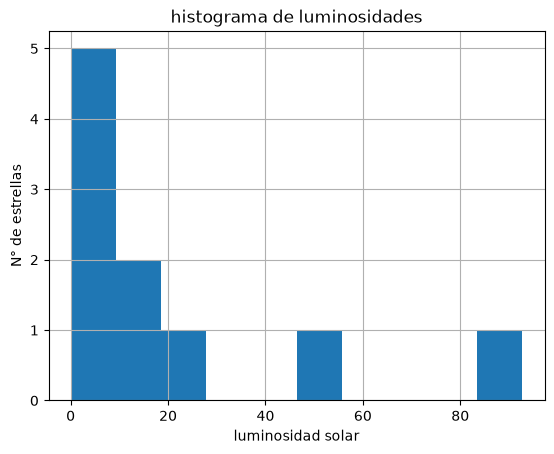

In [83]:
catalogo_10["luminosidad"].hist() #histograma de luminosidades
plt.xlabel("luminosidad solar")
plt.ylabel("N° de estrellas")
plt.title("histograma de luminosidades")

Text(0.5, 1.0, 'histograma de flujos')

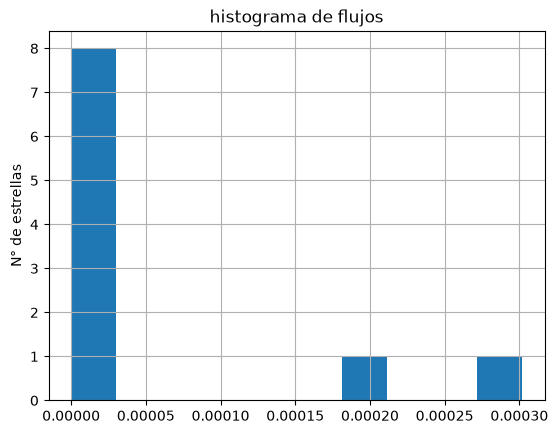

In [82]:
catalogo_10["flujo"].hist() #histograma de flujos
plt.ylabel("N° de estrellas")
plt.title("histograma de flujos")

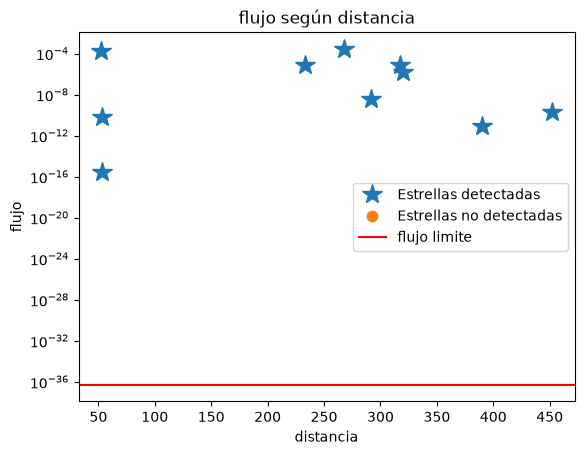

In [75]:
plt.plot(estrellas_d["distancia"], estrellas_d["flujo"], marker="*", ls="None", markersize=15, label="Estrellas detectadas")
plt.plot(estrellas_no_d["distancia"], estrellas_no_d["flujo"], marker=".", ls="None", markersize=15, label="Estrellas no detectadas")
plt.yscale("log")
plt.axhline(flujo_limite, label="flujo limite", c="r")
plt.title("flujo según distancia")
plt.xlabel("distancia [pc]")
plt.ylabel("flujo")
plt.legend()
plt.show()

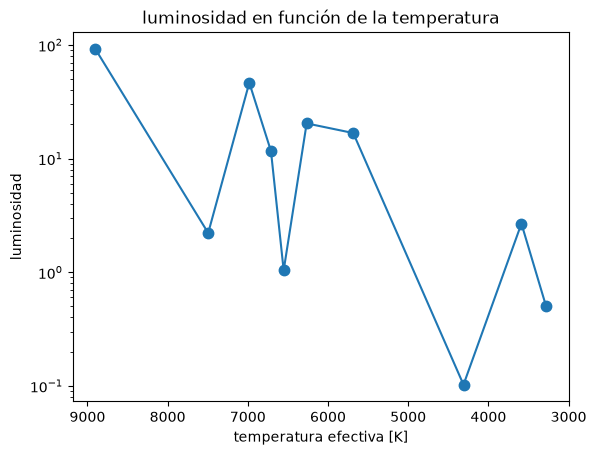

In [74]:
catalogo_10_2 = catalogo_10.sort_values("temperatura_efectiva", ascending=False) # se ponen de mayor a menor las temperaturas
fig, ax = plt.subplots() # use los subplots para usar despues la funcion de invertir un axis
ax.plot(catalogo_10_2["temperatura_efectiva"], catalogo_10_2["luminosidad"], marker=".", markersize=15)
ax.set_yscale("log")
ax.set_title("luminosidad en función de la temperatura")
ax.set_xlabel("temperatura efectiva [K]")
ax.set_ylabel("luminosidad solar")
ax.invert_xaxis() #aqui se invierten el axis
plt.show()